In [17]:
import pandas as pd
import numpy as np
from prophet import Prophet

In [18]:
"""import sys
!"{sys.executable}" -m pip install prophet """

'import sys\n!"{sys.executable}" -m pip install prophet '

In [19]:
Kandi=pd.read_csv("data\Kandi_final.csv")
Parakou=pd.read_csv("data\Parakou_final.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_5236\3890621831.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\Kandi_final.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_5236\3890621831.py:2: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\Parakou_final.csv")


In [20]:
Kandi["Pluviometrie"]

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
4012    0.0
4013    0.0
4014    0.0
4015    0.0
4016    0.0
Name: Pluviometrie, Length: 4017, dtype: float64

In [21]:
def changement(x):
    if x<10:
        return f"0{x}"
    else :
        return f"{x}"
Kandi["Date"]=Kandi["annee"].apply(changement)+"-"+Kandi["mois"].apply(changement)+"-"+Kandi["jour"].apply(changement)
Kandi["Date"]=pd.to_datetime(Kandi["Date"])

Parakou["Date"]=Parakou["annee"].apply(changement)+"-"+Parakou["mois"].apply(changement)+"-"+Parakou["jour"].apply(changement)
Parakou["Date"]=pd.to_datetime(Parakou.Date)

In [22]:
Kandi.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie,Date
0,KANDI_AEROPORT,2015,1,1,979.9,32.0,13.4,32.0,2.4,0.0,2015-01-01
1,KANDI_AEROPORT,2015,1,2,981.4,30.3,17.4,26.0,2.3,0.0,2015-01-02
2,KANDI_AEROPORT,2015,1,3,982.8,29.2,17.7,20.0,3.5,0.0,2015-01-03
3,KANDI_AEROPORT,2015,1,4,983.8,29.0,15.8,20.0,2.8,0.0,2015-01-04
4,KANDI_AEROPORT,2015,1,5,982.7,29.5,13.5,29.0,3.0,0.0,2015-01-05


In [23]:
Kandi.rename(columns={"Date":"ds","Pluviometrie":"y"},inplace=True)
Parakou.rename(columns={"Date":"ds","Pluviometrie":"y"},inplace=True)
Kandi_pluie_train=Kandi[Kandi.annee<2024][["ds","y"]].copy()
Kandi_pluie_test=Kandi[2024<=Kandi.annee][["ds","y"]].copy()

Parakou_pluie_train=Parakou[Parakou.annee<2024][["ds","y"]].copy()
Parakou_pluie_test=Parakou[2024<=Parakou.annee][["ds","y"]].copy()

Kandi_pluie_train

,ds,y
0,2015-01-01,0.0
1,2015-01-02,0.0
2,2015-01-03,0.0
3,2015-01-04,0.0
4,2015-01-05,0.0
...,...,...
3281,2023-12-27,0.0
3282,2023-12-28,0.0
3283,2023-12-29,0.0
3284,2023-12-30,0.0


In [24]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
def calcul_erreur_auto(train,test):
    model=Prophet(yearly_seasonality=True,weekly_seasonality=True,daily_seasonality=True)
    model.fit(train)
    forescat=model.predict(test[["ds"]])
    return {"Resultats":model,"Forecast":forescat,"MAE":mean_absolute_error(test[["y"]],forescat["yhat"]),"RMSE":np.sqrt(mean_squared_error(test[["y"]],forescat["yhat"]))}


In [25]:
Calcul_Kandi=calcul_erreur_auto(Kandi_pluie_train,Kandi_pluie_test)

Calcul_Parakou=calcul_erreur_auto(Parakou_pluie_train,Parakou_pluie_test)

18:52:39 - cmdstanpy - INFO - Chain [1] start processing
18:52:39 - cmdstanpy - INFO - Chain [1] done processing
18:52:40 - cmdstanpy - INFO - Chain [1] start processing
18:52:40 - cmdstanpy - INFO - Chain [1] done processing


In [26]:
Calcul_Kandi

{'Resultats': <prophet.forecaster.Prophet at 0x2836a7afcb0>,
 'Forecast':             ds     trend  yhat_lower  yhat_upper  trend_lower  trend_upper  \
 0   2024-01-01  0.615727  -11.014856   11.880531     0.615727     0.615727   
 1   2024-01-02  0.615687  -12.209277   11.436071     0.615687     0.615687   
 2   2024-01-03  0.615647  -11.535439   10.644096     0.615647     0.615647   
 3   2024-01-04  0.615606  -11.758033   11.150344     0.615606     0.615606   
 4   2024-01-05  0.615566  -11.359725   11.642053     0.615566     0.615566   
 ..         ...       ...         ...         ...          ...          ...   
 726 2025-12-27  0.586650  -11.782593   11.004628     0.581374     0.591165   
 727 2025-12-28  0.586610  -11.929256   10.170716     0.581325     0.591128   
 728 2025-12-29  0.586570  -10.619332   11.780642     0.581277     0.591101   
 729 2025-12-30  0.586530  -11.188590   10.758417     0.581229     0.591078   
 730 2025-12-31  0.586490  -12.267965   11.853722     0.58

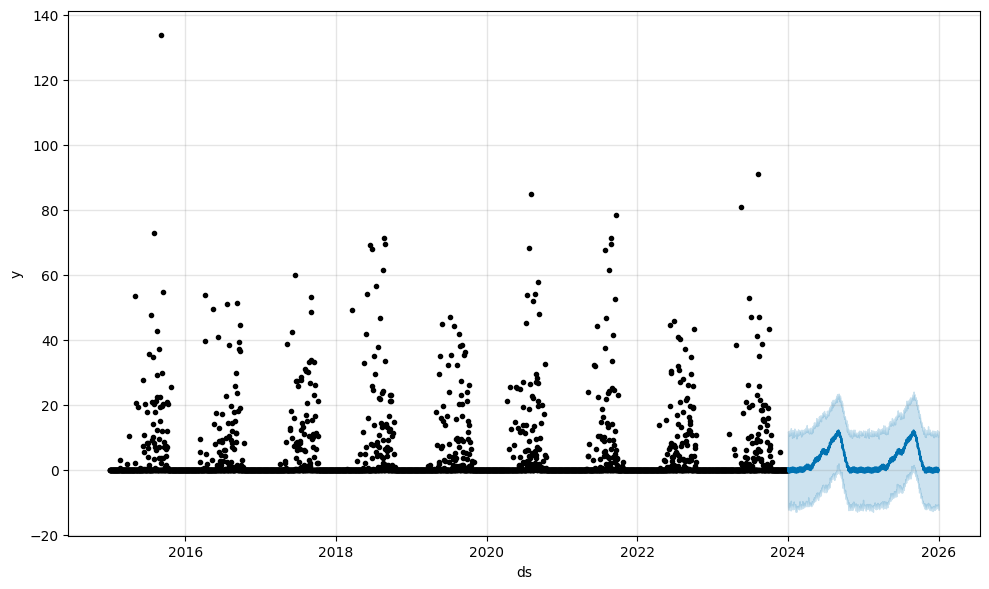

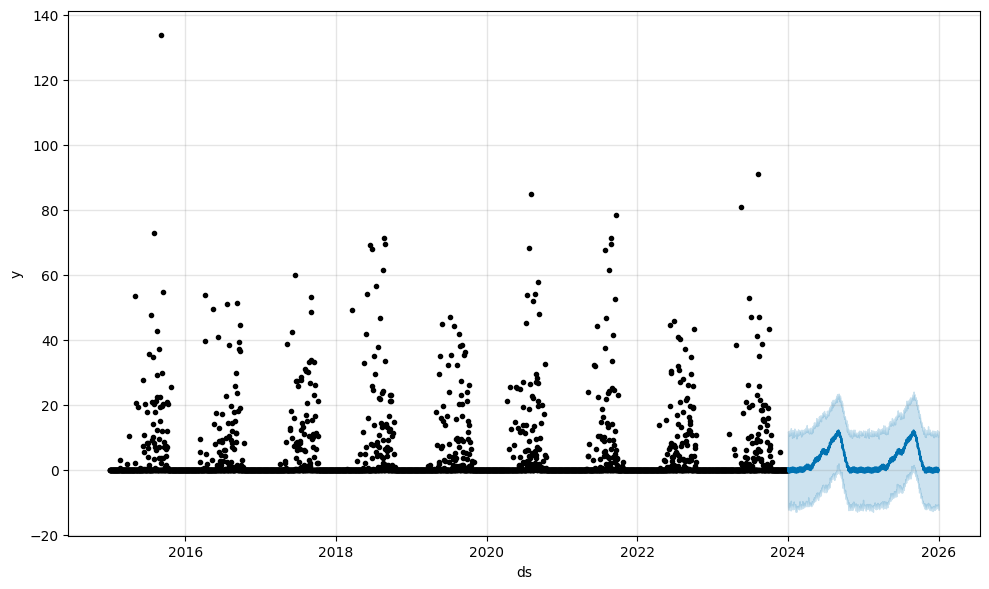

In [27]:
Calcul_Kandi["Resultats"].plot(Calcul_Kandi["Forecast"])

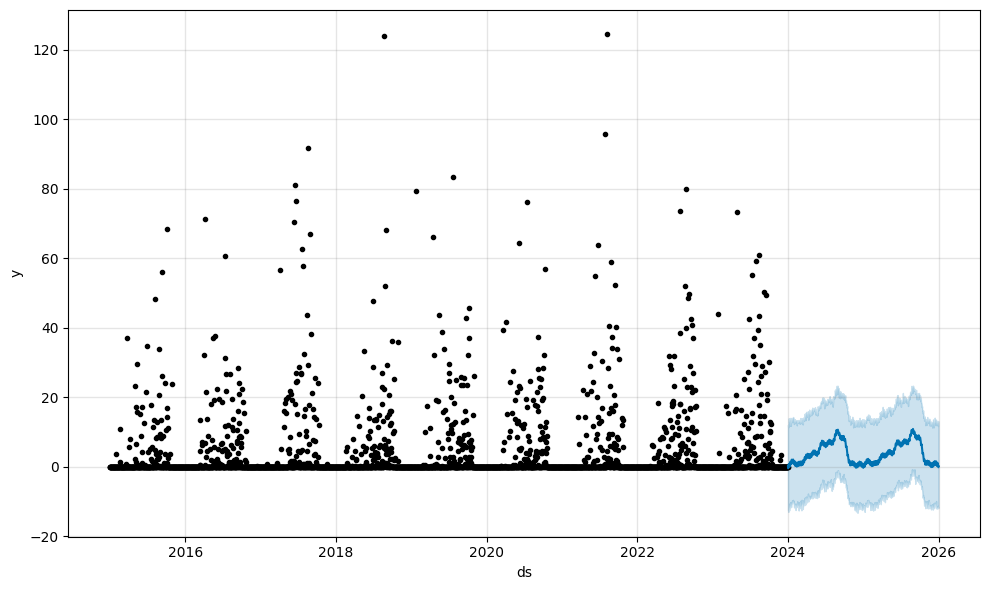

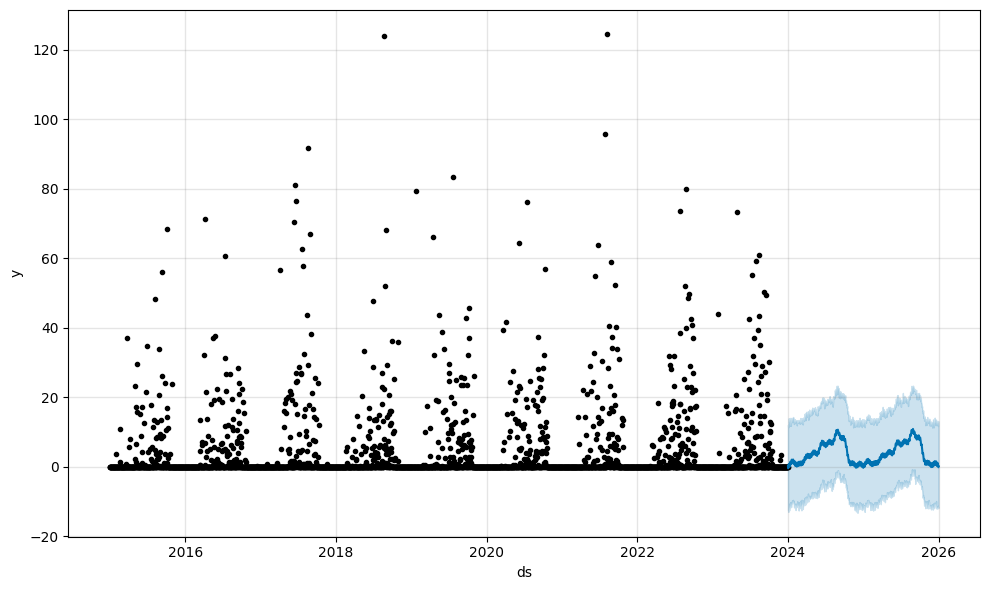

In [28]:
Calcul_Parakou["Resultats"].plot(Calcul_Parakou["Forecast"])

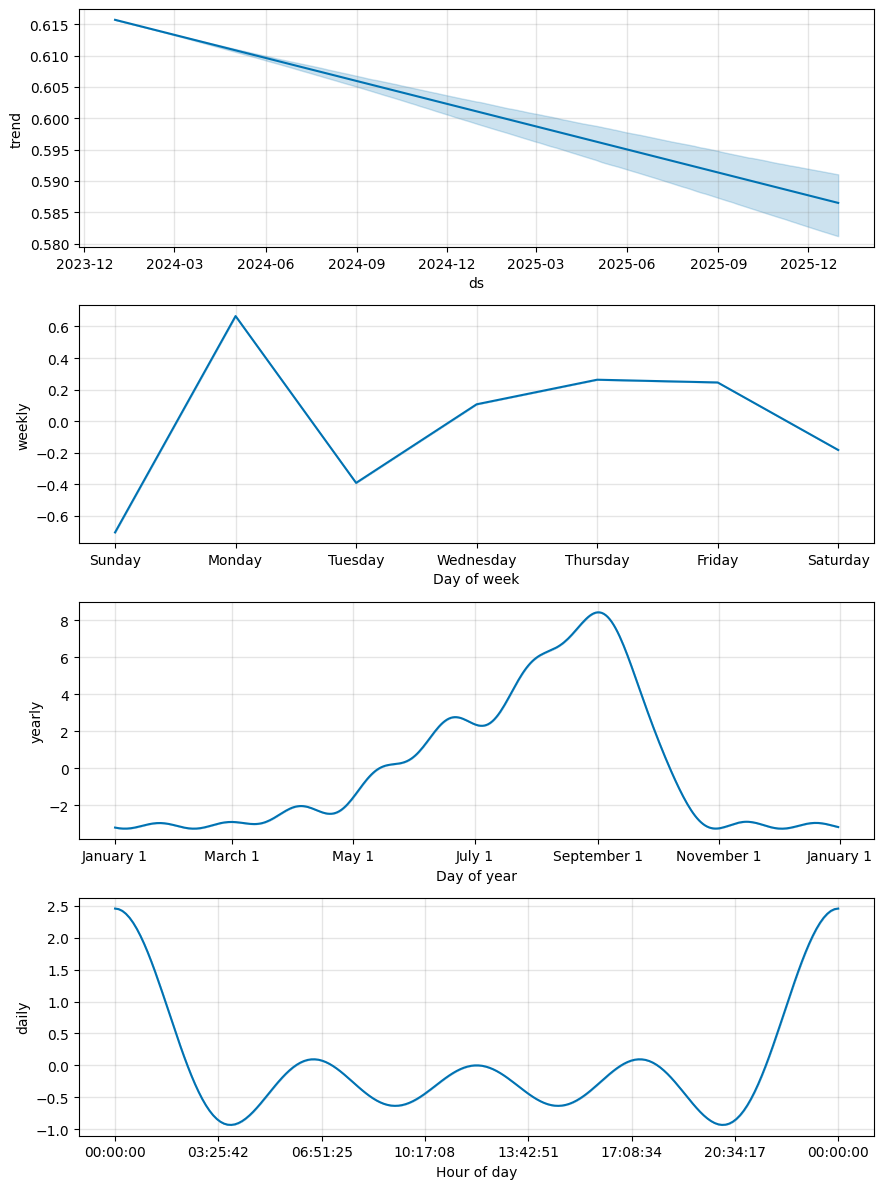

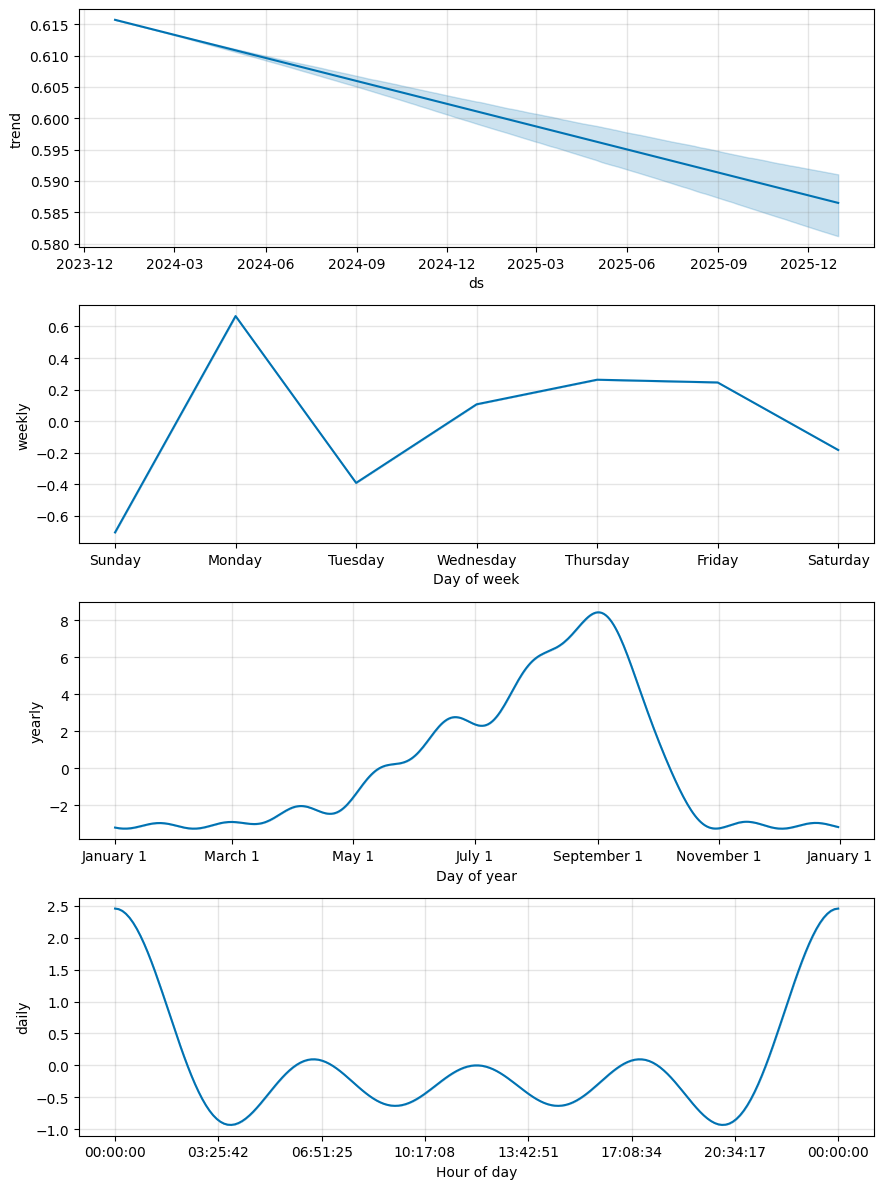

In [29]:
Calcul_Kandi["Resultats"].plot_components(Calcul_Kandi["Forecast"])

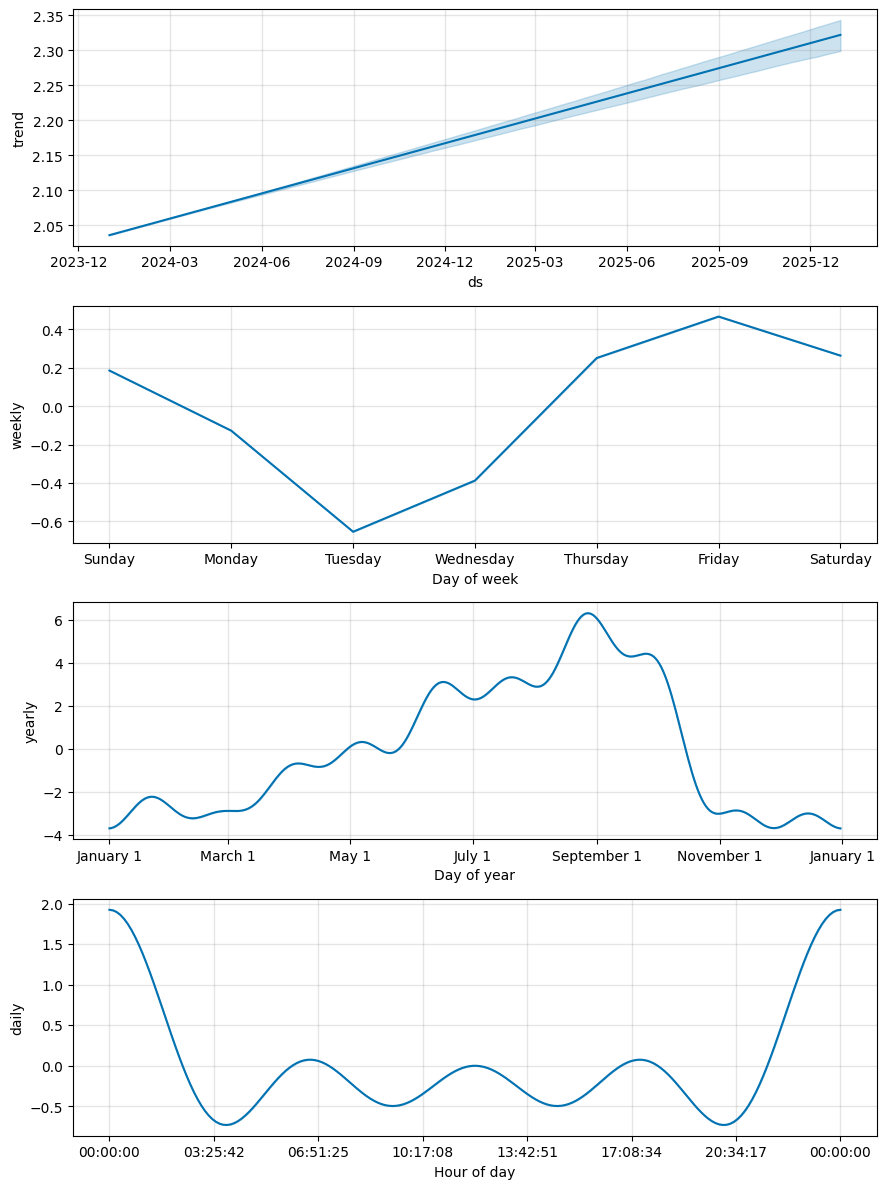

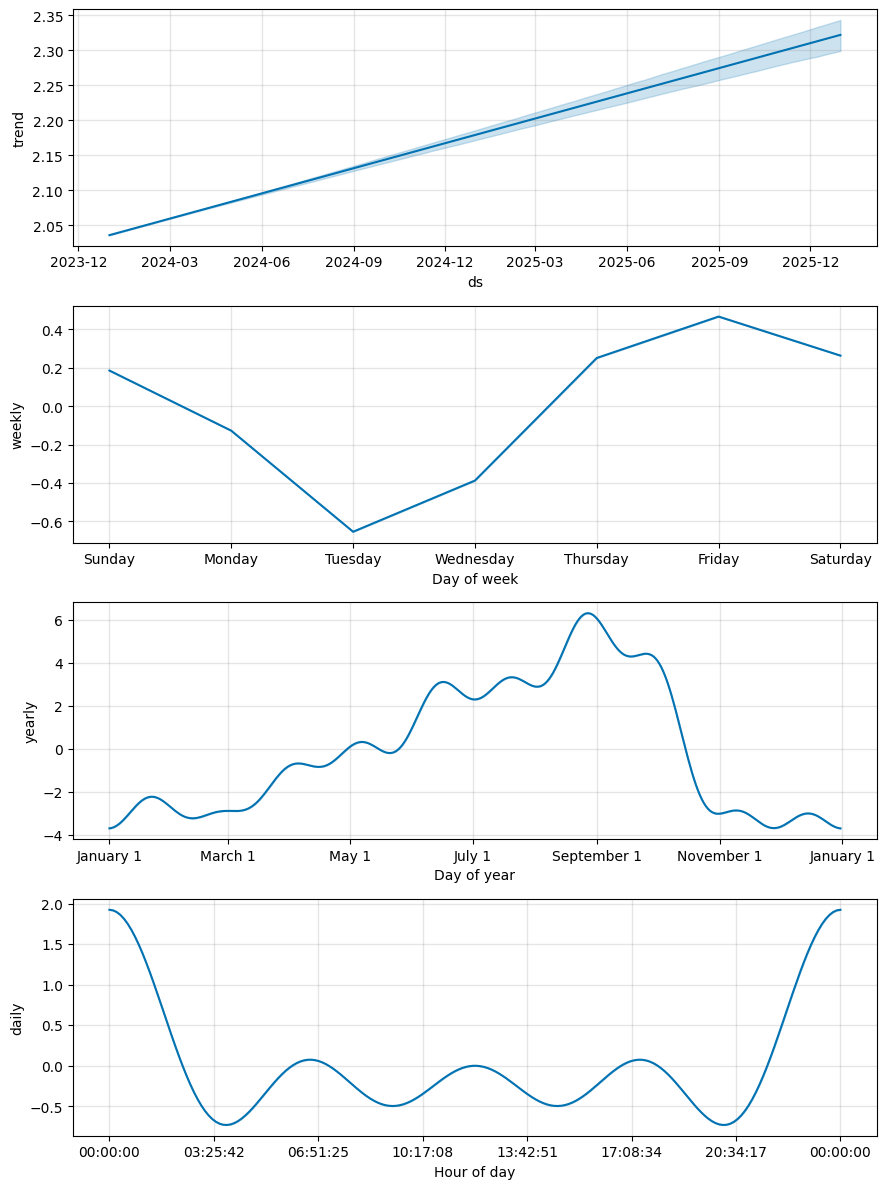

In [30]:
Calcul_Parakou["Resultats"].plot_components(Calcul_Parakou["Forecast"])

In [31]:
resultats=pd.concat([pd.DataFrame({"Station":["Kandi"],"MAE":Calcul_Kandi["MAE"],"RMSE":Calcul_Kandi["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"MAE":Calcul_Parakou["MAE"],"RMSE":Calcul_Parakou["RMSE"]})],axis=0)


resultats

,Station,MAE,RMSE
0,Kandi,4.262941,9.215784
0,Parakou,5.380195,10.922668


In [32]:
resultats.to_csv("data/resultats_prophet_sans_VE.csv",index=False)